0001167619 - Carmine Santella - carmine.santella@studio.unibo.it

# ML4CV Assignment: Person Search on PRW

This is the main notebook of the ML4CV assignment, in its second version. Person search is the joint task of detecting the people in full scene images and recognising a query person among them. The first submission (a Faster R-CNN with FPN, NAE and OIM, trained on Kaggle) reached **27.21% mAP / 59.70% top-1**; it is kept unchanged in `archive/course_submission_v1/`.

This version replaces it with a faithful reimplementation of **SeqNet** (Li & Miao, AAAI 2021), first with SeqNet's ResNet-50 backbone and then with the **SOLIDER Swin-S** backbone (Chen et al., CVPR 2023), a Swin Transformer pre-trained without labels on 4.18 million images of people. All numbers come from the course-provided `eval_search_prw`, which is kept byte-for-byte unchanged in `Scripts/evaluate.py`: only the model side was changed.

| Model | mAP | top-1 |
|---|---|---|
| Course submission (v1) | 27.21 | 59.70 |
| SeqNet, ResNet-50 | 46.40 | 83.08 |
| SeqNet, SOLIDER Swin-S | 60.19 | 87.36 |
| SeqNet, SOLIDER Swin-S + flip test-time augmentation | **63.06** | **88.48** |

**Running the notebook.** The code is in `Scripts/` (see `README.md`). The notebook imports it and reads the training logs, evaluation results and figures stored in the repository, so it runs without a GPU; the cells that need the PRW frames (Section 1) are skipped when the dataset is not found. Training (3–6 hours per model on one NVIDIA L40) and feature extraction ran on the UniBo DISI GPU cluster with `slurm/train_prw.sbatch`; the flags `DO_TRAIN`, `RUN_EVAL` and `RUN_QUALI` below repeat those steps from the notebook.

**Contents:** 1. Dataset · 2. Model architecture · 3. Training and evaluation · 4. Results and analysis (quantitative, negative and qualitative results) · 5. Conclusion

In [1]:
import csv
import json
import os
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import yaml
from IPython.display import Image, Markdown, display
from matplotlib.patches import Rectangle
from PIL import Image as PILImage

print("torch", torch.__version__)

# chart colours: one per model, the same in every chart; chart chrome
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"


def style(ax):
    ax.set_facecolor(SURFACE)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(AXIS)
    ax.tick_params(colors=MUTED, labelcolor=INK2, labelsize=9)
    ax.grid(True, axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)


def show(path, width=1100):
    display(Image(filename=str(path), width=width))

torch 2.7.1+cu128


In [2]:
PROJECT_ROOT = Path.cwd()  # the repository root, where this notebook is
RESULTS = PROJECT_ROOT / "results" / "qualitative"
sys.path.insert(0, str(PROJECT_ROOT / "Scripts"))

# PRW: $PRW_ROOT, the DISI cluster, Kaggle or ./data/PRW (the loader also searches sub-folders)
DATA_CANDIDATES = [os.environ.get("PRW_ROOT", ""),
                   f"/scratch.hpc/{os.environ.get('USER', '')}/data/PRW",
                   "/kaggle/input/datasets/edoardomerli/prw-person-re-identification-in-the-wild",
                   "data/PRW"]

# the trained models: config and output folder (exp_<config name>, as written by train_prw.sbatch)
RUNS = {
    "ResNet-50": ("configs/prw.yaml", "exp_prw"),
    "SOLIDER Swin-S": ("configs/prw_solider_swin_s.yaml", "exp_prw_solider_swin_s"),
    "Swin-S, head lr x10": ("configs/prw_solider_swin_s_head10x.yaml", "exp_prw_solider_swin_s_head10x"),
}

DO_TRAIN = False   # train the three models (3-6 h each on one L40; the Swin-S configs need $WEIGHTS_DIR)
RUN_EVAL = False   # re-extract the features from exp_*/epoch_17.pth and re-run eval_search_prw (GPU)
RUN_QUALI = False  # redraw the qualitative figures from the saved features (CPU, about 10 min)

In [3]:
from config import load_config
from prw import PRW, UNLABELED_PID, resolve_prw_root
from seqnet import SeqNet

DATA_ROOT = None
for candidate in filter(None, DATA_CANDIDATES):
    try:
        DATA_ROOT = resolve_prw_root(candidate)
        break
    except FileNotFoundError:
        pass
HAVE_DATA = DATA_ROOT is not None
print("PRW:", DATA_ROOT if HAVE_DATA else "not found (Section 1 is skipped)")

PRW: /scratch.hpc/carmine.santella/data/PRW


## 1. Dataset

**PRW** (Person Re-identification in the Wild, Zheng et al., CVPR 2017) contains 11,816 frames from 6 cameras on the Tsinghua University campus (five 1920×1080 HD cameras and one 720×576 SD camera), with 932 annotated identities and 2,057 query boxes. The training split has 5,704 frames and the test split, the *gallery*, 6,112. People whose identity is unknown are annotated too, with id −2 (stored as 5555, as in SeqNet).

The task and its evaluation are fixed by the course function `eval_search_prw`:
- A query is a ground-truth box in a test frame. The model has to find the same person in the other 6,111 test frames, from any camera.
- For every gallery frame the model returns its detections (score ≥ `det_thresh`), each with an embedding. All the detections of all frames are ranked by cosine similarity with the query's embedding.
- A detection is correct when it overlaps the query person's box with IoU ≥ min(0.5, wh/((w+10)(h+10))). Each query's average precision is multiplied by the fraction of the query person's gallery appearances that were detected at all, so missed detections cost precision. **mAP** averages this over the 2,057 queries; **top-1** is the share of queries whose best-ranked detection is correct.

The annotations are `[x, y, w, h]` boxes; the loader (`Scripts/prw.py`) converts them to `[x1, y1, x2, y2]` pixel coordinates.

In [4]:
if HAVE_DATA:
    splits = {s: PRW(DATA_ROOT, None, s) for s in ("train", "gallery", "query")}
    rows = []
    for s, title in (("train", "train"), ("gallery", "test (gallery)")):
        annos = splits[s].annotations
        boxes = np.concatenate([a["boxes"].reshape(-1, 4) for a in annos])
        pids = np.concatenate([np.atleast_1d(a["pids"]) for a in annos])
        heights = boxes[:, 3] - boxes[:, 1]
        rows.append(f"| {title} | {len(annos):,} | {len(boxes):,} | {np.mean(pids != UNLABELED_PID):.0%} |"
                    f" {len(set(pids.tolist()) - {UNLABELED_PID})} | {np.median(heights):.0f} px |"
                    f" {np.mean(heights < 100):.0%} |")
    queries = splits["query"].annotations
    display(Markdown(
        "| split | frames | person boxes | labelled | identities | median height | shorter than 100 px |\n"
        "|---|---|---|---|---|---|---|\n" + "\n".join(rows) +
        f"\n\n{len(queries):,} queries of {len({a['pids'] for a in queries})} identities."))
else:
    print("PRW not found: statistics and examples skipped")

| split | frames | person boxes | labelled | identities | median height | shorter than 100 px |
|---|---|---|---|---|---|---|
| train | 5,704 | 18,048 | 83% | 483 | 157 px | 8% |
| test (gallery) | 6,112 | 25,062 | 76% | 544 | 167 px | 8% |

2,057 queries of 450 identities.

The test frames contain more labelled identities than the 450 that are queried: the others only act as distractors. Most people are 100–450 px tall; the 8% shorter than 100 px are the hardest to detect (Section 4.4).

### Dataset visualisation

A training frame with its annotations, and one test identity across cameras: the query box and the person's boxes in gallery frames of other cameras. The changes in scale, viewpoint, lighting and occlusion between cameras are what the re-identification embedding has to overcome.

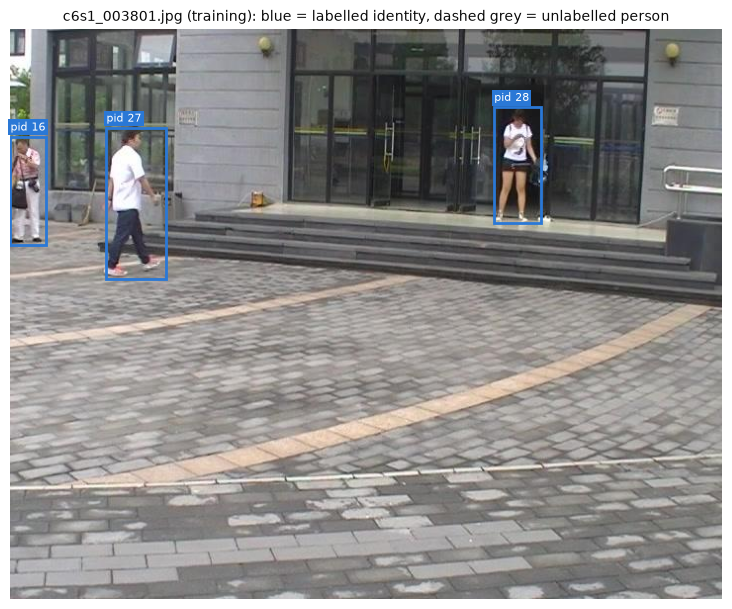

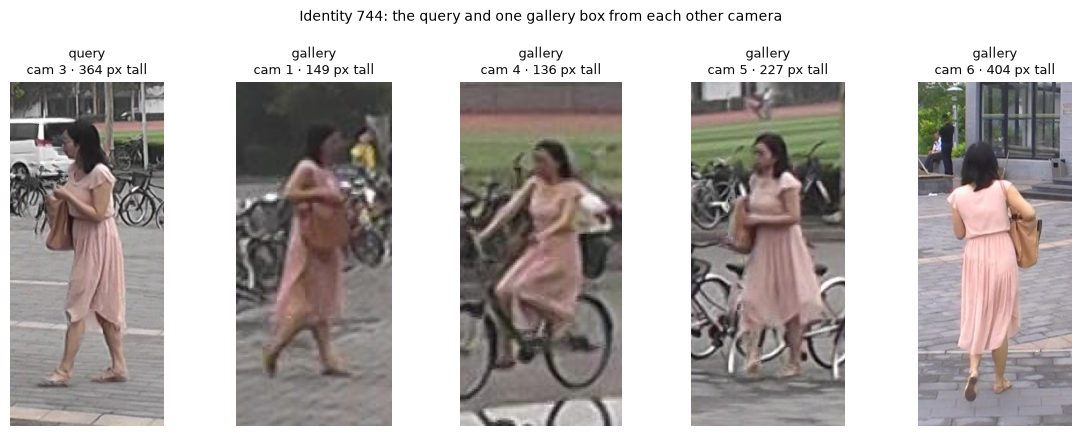

In [5]:
def crop(img, box, aspect=0.45, pad=0.3):
    """Crop around a box with some context (width / height = aspect), inside the frame."""
    x1, y1, x2, y2 = (float(v) for v in box)
    h = min((y2 - y1) * (1 + pad), img.height)
    w = min(max(h * aspect, (x2 - x1) * (1 + pad)), img.width)
    x0 = min(max((x1 + x2 - w) / 2, 0), img.width - w)
    y0 = min(max((y1 + y2 - h) / 2, 0), img.height - h)
    return img.crop((int(x0), int(y0), int(x0 + w), int(y0 + h)))


if HAVE_DATA:
    rng = np.random.default_rng(0)
    busy = [a for a in splits["train"].annotations if (np.atleast_1d(a["pids"]) != UNLABELED_PID).sum() >= 3]
    a = busy[rng.integers(len(busy))]
    fig, ax = plt.subplots(figsize=(13, 7.4))
    ax.imshow(PILImage.open(a["img_path"]).convert("RGB"))
    for b, p in zip(a["boxes"], np.atleast_1d(a["pids"])):
        labelled = p != UNLABELED_PID
        ax.add_patch(Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, lw=2 if labelled else 1.5,
                               edgecolor=SERIES[0] if labelled else "#d9d9d9", ls="-" if labelled else "--"))
        if labelled:
            ax.text(b[0], b[1] - 6, f"pid {p}", color="white", fontsize=8,
                    bbox=dict(facecolor=SERIES[0], lw=0, pad=1.5))
    ax.set_title(f"{a['img_name']} (training): blue = labelled identity, dashed grey = unlabelled person",
                 fontsize=10, color=INK)
    ax.axis("off")
    plt.show()

    # a test identity seen by at least 4 cameras
    gallery = splits["gallery"].annotations
    cams = {}
    for g in gallery:
        for p in np.atleast_1d(g["pids"]):
            cams.setdefault(int(p), set()).add(g["cam_id"])
    candidates = [q for q in queries if len(cams.get(q["pids"], set()) - {q["cam_id"]}) >= 3]
    q = candidates[rng.integers(len(candidates))]
    seen, shots = {q["cam_id"]}, [(q, q["boxes"][0], "query")]
    for g in gallery:
        hit = np.atleast_1d(g["pids"]) == q["pids"]
        if hit.any() and g["cam_id"] not in seen:
            seen.add(g["cam_id"])
            shots.append((g, g["boxes"][hit][0], "gallery"))
    fig, axes = plt.subplots(1, len(shots), figsize=(2.3 * len(shots), 4.4))
    for ax, (anno, box, kind) in zip(axes, shots):
        ax.imshow(crop(PILImage.open(anno["img_path"]).convert("RGB"), box))
        ax.set_title(f"{kind}\ncam {anno['cam_id']} · {box[3] - box[1]} px tall", fontsize=9, color=INK)
        ax.axis("off")
    fig.suptitle(f"Identity {q['pids']}: the query and one gallery box from each other camera", fontsize=10)
    plt.tight_layout()
    plt.show()

## 2. Model architecture

### 2.1 Overview: SeqNet

SeqNet is a two-stage person search network. Detection and re-identification are solved **sequentially**: a standard Faster R-CNN head first refines the proposals, and a second head, with its own weights, computes the identity embedding from the *refined* boxes.

```
image ──► stem: ResNet-50 conv1–res4  |  Swin-S stages 1–3                (stride 16)
             │ feat_res4
             ▼
     Region Proposal Network ──► proposals
             │ RoIAlign 14×14
             ▼
 STAGE 1  Faster R-CNN head: res5  |  Swin stage 4 ──► person score + box refinement
             │ refined boxes (stage-1 detections)
             │ RoIAlign 14×14
             ▼
 STAGE 2  re-ID head: a second res5  |  Swin stage 4 (its own weights)
             ├──► box regressor ─────────────────────► final box
             └──► NAE ──► 256-d embedding: direction = identity   (OIM loss)
                                           norm      = person score (binary cross-entropy)
```

Compared with the course submission, which computed detection and embedding from the same RoI features of the proposals, this has two advantages: the embeddings are pooled from boxes that are already well aligned with the person, and the detection and re-identification heads do not compete for the same features.

At test time:
- **FCS (first classification score):** the score of a gallery detection is stage 1's person score.
- **CWS (confidence-weighted similarity):** each gallery embedding is multiplied by its detection score, so at equal similarity a confident detection ranks above an uncertain one.
- A query skips the detector: its embedding is computed from its ground-truth box through stage 2.

### 2.2 Norm-Aware Embedding (NAE)

The NAE (Chen et al., CVPR 2020) takes two features of each box from the re-ID head: `feat_res4`, the average-pooled 14×14 RoI input (1024 channels for ResNet-50, 384 for Swin-S), and `feat_res5`, the average-pooled head output (2048 / 768 channels). Each is projected to 128 dimensions (`Linear` + `BatchNorm`) and the two are concatenated into a 256-d vector, which is then split into two components:

- the **direction** (the L2-normalised vector) encodes the *identity* and is compared with cosine similarity;
- the **norm**, rescaled by a `BatchNorm1d`, is the *person vs background* logit, trained with binary cross-entropy.

Re-identification ("which person?") and detection ("is it a person?") are different questions; giving them orthogonal components of the same vector lets each be optimised without distorting the other.

### 2.3 OIM loss

The Online Instance Matching loss (Xiao et al., CVPR 2017) supervises the direction. It keeps two memories:
- a **lookup table (LUT)** with one feature per labelled training identity (482), updated with momentum $m = 0.5$;
- a **circular queue (CQ)** of the 500 most recent unlabelled people, used as extra negatives.

With $\mathbf{f}_i$ the embedding of a labelled box, $\mathbf{v}_k$ the LUT entries and $\mathbf{u}_q$ the CQ entries, it is a softmax cross-entropy over scaled cosine similarities ($\tau = 30$):

$$\mathcal{L}_{\text{OIM}} = -\frac{1}{N} \sum_{i} \log \frac{e^{\tau \cdot \mathbf{f}_i^\top \mathbf{v}_{y_i}}}{\sum_{k} e^{\tau \cdot \mathbf{f}_i^\top \mathbf{v}_k} + \sum_{q} e^{\tau \cdot \mathbf{f}_i^\top \mathbf{u}_q}}$$

The training loss is the sum of seven terms: RPN classification and regression, stage-1 classification and regression (the latter weighted ×10, as in SeqNet), stage-2 classification (the NAE norm) and regression, and OIM.

### 2.4 SOLIDER Swin-S backbone

The second model keeps SeqNet unchanged and replaces the ResNet-50 parts with a **Swin Transformer Small**, split as in SOLIDER-PersonSearch: stages 1–3 (stride 16, 384 channels) are the stem, and the patch merging of stage 3 followed by stage 4 (768 channels) form each RoI head, followed by average pooling. The stem and the stage-1 head share one Swin; the re-ID head is a copy of it.

The weights come from **SOLIDER**, which pre-trains the Swin without labels on LUPerson (4.18M images of people) with DINO-style self-distillation plus a clustering of the image tokens into semantic body parts. A **semantic controller** — a scalar λ fed to small linear layers that scale and shift the output of every stage — sets at fine-tuning time how much the features favour appearance (small λ) or semantics (large λ); SOLIDER-PersonSearch uses λ = 0.6. ImageNet features are generic; these features are learned on people only, so the re-ID embedding starts from features that already describe clothing, textures and body parts.

In [6]:
PARTS = {  # for Swin-S the stem and the stage-1 head are one shared Swin, counted under "backbone."
    "stem + stage-1 head": ("backbone.", "roi_heads.box_head."),
    "RPN": ("rpn.",),
    "stage-1 predictor": ("roi_heads.faster_rcnn_predictor.",),
    "re-ID head": ("roi_heads.reid_head.",),
    "NAE": ("roi_heads.embedding_head.",),
    "stage-2 box regressor": ("roi_heads.box_predictor.",),
}
rows = []
for name in ("ResNet-50", "SOLIDER Swin-S"):
    cfg = load_config(RUNS[name][0], ["MODEL.BACKBONE.PRETRAINED", "false"])  # weights: see the checkpoints
    model = SeqNet(cfg)
    named = list(model.named_parameters())
    counts = [sum(p.numel() for n, p in named if n.startswith(prefixes)) for prefixes in PARTS.values()]
    trainable = sum(p.numel() for _, p in named if p.requires_grad)
    rows.append(f"| {name} | " + " | ".join(f"{c / 1e6:.2f}" for c in counts) +
                f" | **{sum(counts) / 1e6:.2f}** | {trainable / 1e6:.2f} |")
    del model
display(Markdown("Parameters (millions):\n\n| model | " + " | ".join(PARTS) + " | total | trainable |\n"
                 "|---|" + "---|" * (len(PARTS) + 2) + "\n" + "\n".join(rows)))

Parameters (millions):

| model | stem + stage-1 head | RPN | stage-1 predictor | re-ID head | NAE | stage-2 box regressor | total | trainable |
|---|---|---|---|---|---|---|---|---|
| ResNet-50 | 23.51 | 9.52 | 0.02 | 14.96 | 0.39 | 0.02 | **48.42** | 48.41 |
| SOLIDER Swin-S | 48.85 | 1.36 | 0.01 | 48.85 | 0.15 | 0.01 | **99.22** | 99.22 |

For ResNet-50, `conv1` and its batch norm are frozen, as in SeqNet. For Swin-S the re-ID head is a full copy of the Swin, as in SOLIDER-PersonSearch: its stages 1–3 are never used and get no gradient (33.5M parameters, a third of the total).

## 3. Training and evaluation

### 3.1 Configuration

| | ResNet-50 | SOLIDER Swin-S |
|---|---|---|
| Pre-training | ImageNet (torchvision `IMAGENET1K_V1`) | SOLIDER on LUPerson, λ = 0.6 |
| Batch size | 5 | 3 |
| Learning rate | 0.003 | 0.0003 |
| Optimizer | SGD, momentum 0.9, weight decay 5e-4 | same |
| Schedule | linear warm-up over the first epoch, 18 epochs, ×0.1 for the last 2 | same |
| Input | shorter side 900 px, longer side ≤ 1500 px, random horizontal flip | same |
| Gradient clipping | norm 10 | same |
| Precision | fp32 | fp32 |
| Hardware, time | 1× NVIDIA L40, 3 h 20 min | 1× NVIDIA L40, 6 h 00 min |

Both recipes are the published ones (SeqNet's PRW configuration and SOLIDER-PersonSearch's script for Swin-S); we did not tune them. Unlike the course submission, there is no cosine schedule, Nesterov momentum, mixed precision or LUT warm-start, and no setting was chosen on the test set. The table below is read from the configuration each run saved (`–`: the setting did not exist yet when that run was trained).

In [7]:
KEYS = ["MODEL.BACKBONE.NAME", "MODEL.BACKBONE.SEMANTIC_WEIGHT", "INPUT.BATCH_SIZE_TRAIN", "SOLVER.BASE_LR",
        "SOLVER.HEAD_LR_MULT", "SOLVER.MAX_EPOCHS", "SOLVER.LR_DECAY_MILESTONES", "SOLVER.WEIGHT_DECAY",
        "INPUT.MIN_SIZE", "INPUT.MAX_SIZE", "MODEL.LOSS.LUT_SIZE", "MODEL.LOSS.CQ_SIZE",
        "MODEL.LOSS.OIM_MOMENTUM", "MODEL.LOSS.OIM_SCALAR", "SOLVER.LW_PROPOSAL_REG", "AMP"]


def get(cfg, key):
    for k in key.split("."):
        cfg = cfg.get(k, "–") if isinstance(cfg, dict) else "–"
    return cfg


used = {name: yaml.safe_load(open(PROJECT_ROOT / out / "config.yaml")) for name, (_, out) in RUNS.items()}
display(Markdown("| key | " + " | ".join(used) + " |\n|---|" + "---|" * len(used) + "\n" +
                 "\n".join(f"| `{k}` | " + " | ".join(str(get(c, k)) for c in used.values()) + " |" for k in KEYS)))

| key | ResNet-50 | SOLIDER Swin-S | Swin-S, head lr x10 |
|---|---|---|---|
| `MODEL.BACKBONE.NAME` | resnet50 | swin_small | swin_small |
| `MODEL.BACKBONE.SEMANTIC_WEIGHT` | – | 0.6 | 0.6 |
| `INPUT.BATCH_SIZE_TRAIN` | 5 | 3 | 3 |
| `SOLVER.BASE_LR` | 0.003 | 0.0003 | 0.0003 |
| `SOLVER.HEAD_LR_MULT` | – | – | 10.0 |
| `SOLVER.MAX_EPOCHS` | 18 | 18 | 18 |
| `SOLVER.LR_DECAY_MILESTONES` | [16] | [16] | [16] |
| `SOLVER.WEIGHT_DECAY` | 0.0005 | 0.0005 | 0.0005 |
| `INPUT.MIN_SIZE` | 900 | 900 | 900 |
| `INPUT.MAX_SIZE` | 1500 | 1500 | 1500 |
| `MODEL.LOSS.LUT_SIZE` | 482 | 482 | 482 |
| `MODEL.LOSS.CQ_SIZE` | 500 | 500 | 500 |
| `MODEL.LOSS.OIM_MOMENTUM` | 0.5 | 0.5 | 0.5 |
| `MODEL.LOSS.OIM_SCALAR` | 30.0 | 30.0 | 30.0 |
| `SOLVER.LW_PROPOSAL_REG` | 10.0 | 10.0 | 10.0 |
| `AMP` | off | off | off |

### 3.2 Training

Training ran on the UniBo DISI GPU cluster, one SLURM job per configuration:

```bash
sbatch slurm/train_prw.sbatch                                              # ResNet-50
CFG=configs/prw_solider_swin_s.yaml sbatch slurm/train_prw.sbatch          # SOLIDER Swin-S
CFG=configs/prw_solider_swin_s_head10x.yaml sbatch slurm/train_prw.sbatch  # Section 4.3
```

The job runs `Scripts/train.py`, saves a checkpoint after every epoch (and resumes from it if the job is requeued), then evaluates the last epoch. With `DO_TRAIN = True` the next cell runs the same training from the notebook.

In [8]:
if DO_TRAIN:
    for name, (cfg_file, out) in RUNS.items():
        print(f"=== {name}")
        subprocess.run([sys.executable, "Scripts/train.py", "--cfg", cfg_file, "--data-root", str(DATA_ROOT),
                        "--output-dir", out, "--resume", "auto"], check=True)
else:
    print("DO_TRAIN = False: using the training logs in exp_*/")

DO_TRAIN = False: using the training logs in exp_*/


### 3.3 Training curves

Average losses per epoch, from `exp_*/epoch_log.csv` (log scale). The dotted line marks the learning-rate drop.

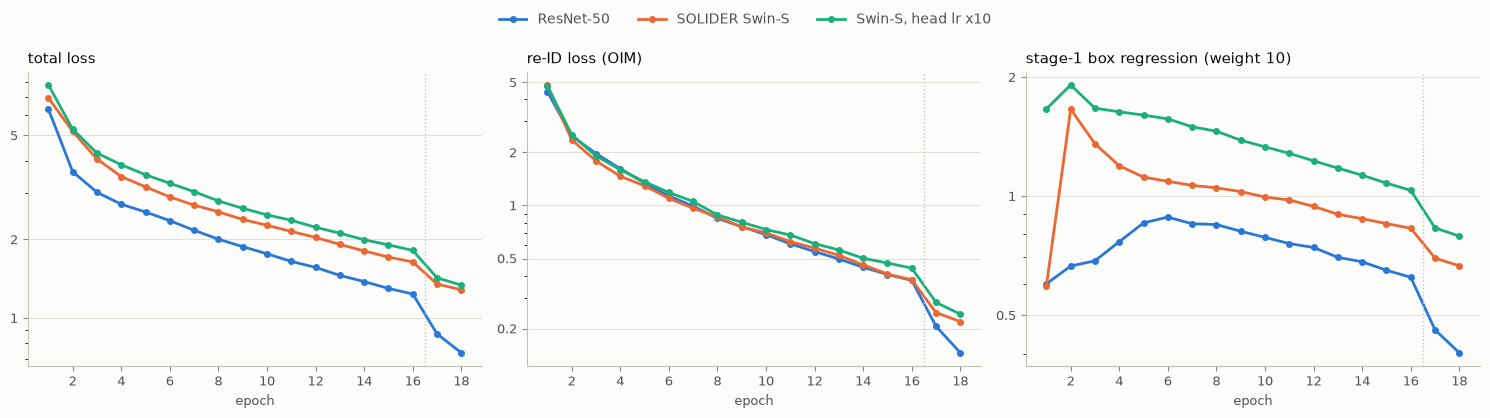

Last epoch:

| model | total loss | re-ID loss (OIM) | stage-1 box regression (weight 10) |
|---|---|---|---|
| ResNet-50 | 0.736 | 0.146 | 0.402 |
| SOLIDER Swin-S | 1.283 | 0.219 | 0.667 |
| Swin-S, head lr x10 | 1.337 | 0.241 | 0.792 |

In [9]:
from matplotlib.ticker import FuncFormatter, LogLocator, MaxNLocator

logs = {name: list(csv.DictReader(open(PROJECT_ROOT / out / "epoch_log.csv"))) for name, (_, out) in RUNS.items()}
panels = [("loss", "total loss"), ("loss_box_reid", "re-ID loss (OIM)"),
          ("loss_proposal_reg", "stage-1 box regression (weight 10)")]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), facecolor=SURFACE)
for ax, (key, title) in zip(axes, panels):
    style(ax)
    for color, (name, rows) in zip(SERIES, logs.items()):
        ax.plot([int(r["epoch"]) + 1 for r in rows], [float(r[key]) for r in rows], color=color, lw=2,
                marker="o", ms=4, label=name)
    ax.axvline(16.5, color=AXIS, lw=1, ls=":")
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(LogLocator(subs=(1, 2, 5)))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    ax.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: ""))
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_title(title, fontsize=11, color=INK, loc="left")
    ax.set_xlabel("epoch", color=INK2, fontsize=9)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=3, frameon=False, fontsize=10,
           labelcolor=INK2)
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()

display(Markdown("Last epoch:\n\n| model | " + " | ".join(t for _, t in panels) + " |\n|---|---|---|---|\n" +
                 "\n".join(f"| {name} | " + " | ".join(f"{float(rows[-1][k]):.3f}" for k, _ in panels) + " |"
                           for name, rows in logs.items())))

All runs converge smoothly, and every loss drops again with the learning rate. Two observations (the losses of different models are only roughly comparable, since batch size and learning rate differ):
- **ResNet-50 ends with the lowest re-ID loss** (0.146 against 0.219 for Swin-S), yet Swin-S is 13.8 mAP better on the test set. The OIM loss measures how well the 482 *training* identities are separated, not how well the features generalise to the 450 unseen *test* identities. The course submission had already noticed this gap between the training objective and the test metric (its Section 4.4).
- **Swin-S keeps a higher stage-1 box regression loss** (0.667 against 0.402), in line with its lower detection AP (Section 3.4). Raising the learning rate of the heads did not lower it (0.792, Section 4.3).

### 3.4 Evaluation

`Scripts/eval_prw.py` runs the model on the 6,112 gallery frames and the 2,057 query boxes and passes the results to `eval_search_prw`:
- **gallery:** detections with score ≥ 0.5 (`SCORE_THRESH_TEST`, SeqNet's default), after NMS, at most 300 per frame, with CWS-weighted embeddings;
- **queries:** the embedding of each ground-truth query box;
- **`det_thresh`:** evaluated at 0.5, 0.6, 0.7 and 0.8. The results are practically identical (last column), because detections below 0.5 are already removed and CWS down-weights uncertain ones. We report 0.5, SeqNet's value. Unlike the course submission, where tuning this threshold on the test set was worth +2.18 mAP, there is nothing to tune;
- **flip test-time augmentation** (`--flip-tta`): every gallery frame and query is processed a second time mirrored, with the same boxes mirrored; the two L2-normalised embeddings are averaged and normalised again, then CWS is applied. The detections do not change. It doubles the re-identification cost at test time and needs no retraining.

The detection recall and AP are computed on all the annotated people of the gallery (IoU ≥ 0.5).

In [10]:
EVALS = [("ResNet-50", "exp_prw", "eval_epoch_17.json"),
         ("SOLIDER Swin-S", "exp_prw_solider_swin_s", "eval_epoch_17.json"),
         ("SOLIDER Swin-S + flip TTA", "exp_prw_solider_swin_s", "eval_epoch_17_flip.json"),
         ("Swin-S, head lr x10", "exp_prw_solider_swin_s_head10x", "eval_epoch_17.json")]

if RUN_EVAL:
    for name, out, result in EVALS:
        args = [sys.executable, "Scripts/eval_prw.py", "--ckpt", f"{out}/epoch_17.pth", "--data-root",
                str(DATA_ROOT), "--out", f"{out}/{result}"]
        args += ["--flip-tta"] if "flip" in result else ["--cache", f"{out}/features_epoch_17.pt"]
        subprocess.run(args, check=True)

rows = []
for name, out, result in EVALS:
    r = json.load(open(PROJECT_ROOT / out / result))
    at = {s["det_thresh"]: s for s in r["search"]}
    maps = [s["mAP"] for s in r["search"]]
    rows.append(f"| {name} | {100 * r['detection']['recall']:.2f} | {100 * r['detection']['ap']:.2f} |"
                f" **{100 * at[0.5]['mAP']:.2f}** | **{100 * at[0.5]['top1']:.2f}** |"
                f" {100 * (max(maps) - min(maps)):.2f} |")
display(Markdown("PRW test set, `eval_search_prw` at `det_thresh` 0.5 (%):\n\n"
                 "| model | detection recall | detection AP | mAP | top-1 | mAP spread over det_thresh 0.5–0.8 |\n"
                 "|---|---|---|---|---|---|\n" + "\n".join(rows)))

PRW test set, `eval_search_prw` at `det_thresh` 0.5 (%):

| model | detection recall | detection AP | mAP | top-1 | mAP spread over det_thresh 0.5–0.8 |
|---|---|---|---|---|---|
| ResNet-50 | 96.45 | 94.02 | **46.40** | **83.08** | 0.03 |
| SOLIDER Swin-S | 95.66 | 91.49 | **60.19** | **87.36** | 0.01 |
| SOLIDER Swin-S + flip TTA | 95.66 | 91.49 | **63.06** | **88.48** | 0.02 |
| Swin-S, head lr x10 | 95.99 | 92.26 | **58.79** | **85.85** | 0.01 |

---

## 4. Results and analysis

### 4.1 Final result

| Metric | SOLIDER Swin-S + SeqNet | + flip test-time augmentation |
|---|---|---|
| **mAP** | 60.19% | **63.06%** |
| **Top-1** | 87.36% | **88.48%** |
| `det_thresh` | 0.5 (SeqNet's default, not tuned) | 0.5 |
| Detection recall / AP (gallery) | 95.66% / 91.49% | same detections |

Compared with the course submission (27.21% / 59.70%), this is **+35.85 mAP and +28.78 top-1** with flip test-time augmentation, and +32.98 / +27.66 without it.

### 4.2 Progression

| # | Configuration | mAP | Top-1 | $\Delta$ mAP |
|---|---|---|---|---|
| 1 | Course submission: Faster R-CNN FPN v2 + NAE + OIM (`det_thresh` tuned on the test set) | 27.21 | 59.70 | — |
| 2 | SeqNet reimplementation, ResNet-50, official recipe | 46.40 | 83.08 | +19.19 |
| 3 | + SOLIDER Swin-S backbone (SOLIDER-PersonSearch recipe) | 60.19 | 87.36 | +13.79 |
| 4 | + flip test-time augmentation (same checkpoint) | **63.06** | **88.48** | +2.87 |

- **Row 2** changes the whole design at once, so it is not the ablation of a single component. It reproduces the SeqNet paper (46.7 / 83.4 without CBGM) within 0.3 mAP. A parity test against the official code also gave identical parameters, losses, gradients and outputs on the same input, so the gap between rows 1 and 2 comes from SeqNet's design and recipe, not from a different implementation of the same ideas.
- **Row 3** is the largest gain from a single change. It also slightly exceeds the result reported by SOLIDER-PersonSearch for the same model (59.84 / 86.73).
- **Row 4** changes only the inference.

For reference, recent methods report up to about 62 mAP on PRW without post-processing (e.g. SEAS 60.5, SPNet-L 61.2, DiffPS 62.0, as reported by their authors), and none of them uses test-time augmentation. The like-for-like comparison is therefore 60.19, which is in line with them; 63.06 is above all of them, but uses the augmentation.

### 4.3 Negative results

| Configuration | mAP | Top-1 | Detection recall | Detection AP | $\Delta$ mAP |
|---|---|---|---|---|---|
| SOLIDER Swin-S (reference) | 60.19 | 87.36 | 95.66 | 91.49 | — |
| + head learning rate ×10 | 58.79 | 85.85 | 95.99 | 92.26 | $-1.40$ |

**Motivation.** Swin-S detects worse than ResNet-50 (AP 91.49 against 94.02). SOLIDER's learning rate, 3e-4, is ten times smaller than SeqNet's, and it also applies to the layers that start from random weights: the RPN head, the two box predictors and the NAE. `SOLVER.HEAD_LR_MULT 10` trains these layers at 0.003 and keeps 3e-4 for the pre-trained Swin.

**Outcome.** Detection improved a little (+0.33 recall, +0.77 AP), but person search got worse (−1.40 mAP, −1.51 top-1) and the re-ID loss ended higher (0.241 against 0.219). The likely cause is the NAE projection, which also received the higher learning rate and is the layer that produces the embedding. A variant that raises only the detection layers would separate the two effects. We did not run it, because the qualitative analysis (Section 4.4) shows that the detection gap concerns small people, which a learning rate is unlikely to fix.

The negative results of the course submission (scene-level random erasing, batch-hard triplet loss, LUT warm-start, Soft-NMS) concern the earlier model; they are documented in `archive/course_submission_v1/main.ipynb`.

### 4.4 Qualitative results

The course submission had no qualitative results. Here they are produced by `Scripts/qualitative.py`, which does not need the model: it reads the gallery and query features saved during the evaluation (`exp_*/features_epoch_17.pt`) and ranks them with the unchanged `eval_search_prw`. The figures therefore show exactly the retrievals behind the numbers above (the script prints the same mAP). Each retrieved box is then compared with the people annotated in its frame:
- **correct:** the query person (the course function's flag);
- **another labelled person** (with their identity), or **an unlabelled person**;
- **right person, inaccurate box:** the box overlaps the query person, but with an IoU below the evaluation threshold (and at least 0.3);
- **no annotated person:** a false detection, or a person that PRW did not annotate in that frame.

Examples are drawn at random, with a fixed seed, inside each group, and every figure gives the size of its group, so they are representative rather than hand-picked. The figures compare the two models without test-time augmentation. Colours: **blue** = query, **green** = the query person retrieved, **red** = anyone or anything else, **dashed yellow** = where the query person really is in that frame, **thin grey** = the other annotated people.

In [11]:
if RUN_QUALI:
    subprocess.run([sys.executable, "Scripts/qualitative.py", "--data-root", str(DATA_ROOT), "--out", str(RESULTS),
                    "--run", "SOLIDER Swin-S", "exp_prw_solider_swin_s/features_epoch_17.pt",
                    "--run", "ResNet-50", "exp_prw/features_epoch_17.pt"], check=True)

summary = json.load(open(RESULTS / "summary.json"))
GROUPS = {"correct": "correct", "never_detected": "query person never detected",
          "same_frame": "right frame, wrong person", "lookalike": "another labelled person",
          "unlabeled": "an unlabelled person", "loose_box": "right person, inaccurate box",
          "no_person": "no annotated person under the box"}
runs = summary["runs"]
n = runs[0]["n_queries"]
lines = ["| top-1 result | " + " | ".join(r["label"] for r in runs) + " |", "|---|" + "---|" * len(runs)]
for g, text in GROUPS.items():
    lines.append(f"| {text} | " + " | ".join(f"{r['top1_groups'][g]} ({100 * r['top1_groups'][g] / n:.1f}%)"
                                            for r in runs) + " |")
for k in ("top5", "top10"):
    lines.append(f"| query person within the first {k[3:]} | " + " | ".join(f"{100 * r[k]:.2f}%" for r in runs) + " |")
lines.append("| query person's gallery appearances detected | " + " | ".join(
    f"{100 * r['query_person_frames_detected'] / r['query_person_frames']:.2f}%" for r in runs) + " |")
display(Markdown("\n".join(lines) + f"\n\nSwin-S fixes the top-1 result of {summary['compare']['fixed']} queries"
                 f" that ResNet-50 gets wrong, and gets {summary['compare']['broken']} wrong that ResNet-50"
                 f" gets right (out of {n})."))

| top-1 result | SOLIDER Swin-S | ResNet-50 |
|---|---|---|
| correct | 1797 (87.4%) | 1709 (83.1%) |
| query person never detected | 0 (0.0%) | 0 (0.0%) |
| right frame, wrong person | 15 (0.7%) | 5 (0.2%) |
| another labelled person | 125 (6.1%) | 222 (10.8%) |
| an unlabelled person | 60 (2.9%) | 77 (3.7%) |
| right person, inaccurate box | 7 (0.3%) | 1 (0.0%) |
| no annotated person under the box | 53 (2.6%) | 43 (2.1%) |
| query person within the first 5 | 94.17% | 92.37% |
| query person within the first 10 | 95.38% | 94.36% |
| query person's gallery appearances detected | 97.81% | 98.23% |

Swin-S fixes the top-1 result of 186 queries that ResNet-50 gets wrong, and gets 98 wrong that ResNet-50 gets right (out of 2057).

#### Random queries (Swin-S)

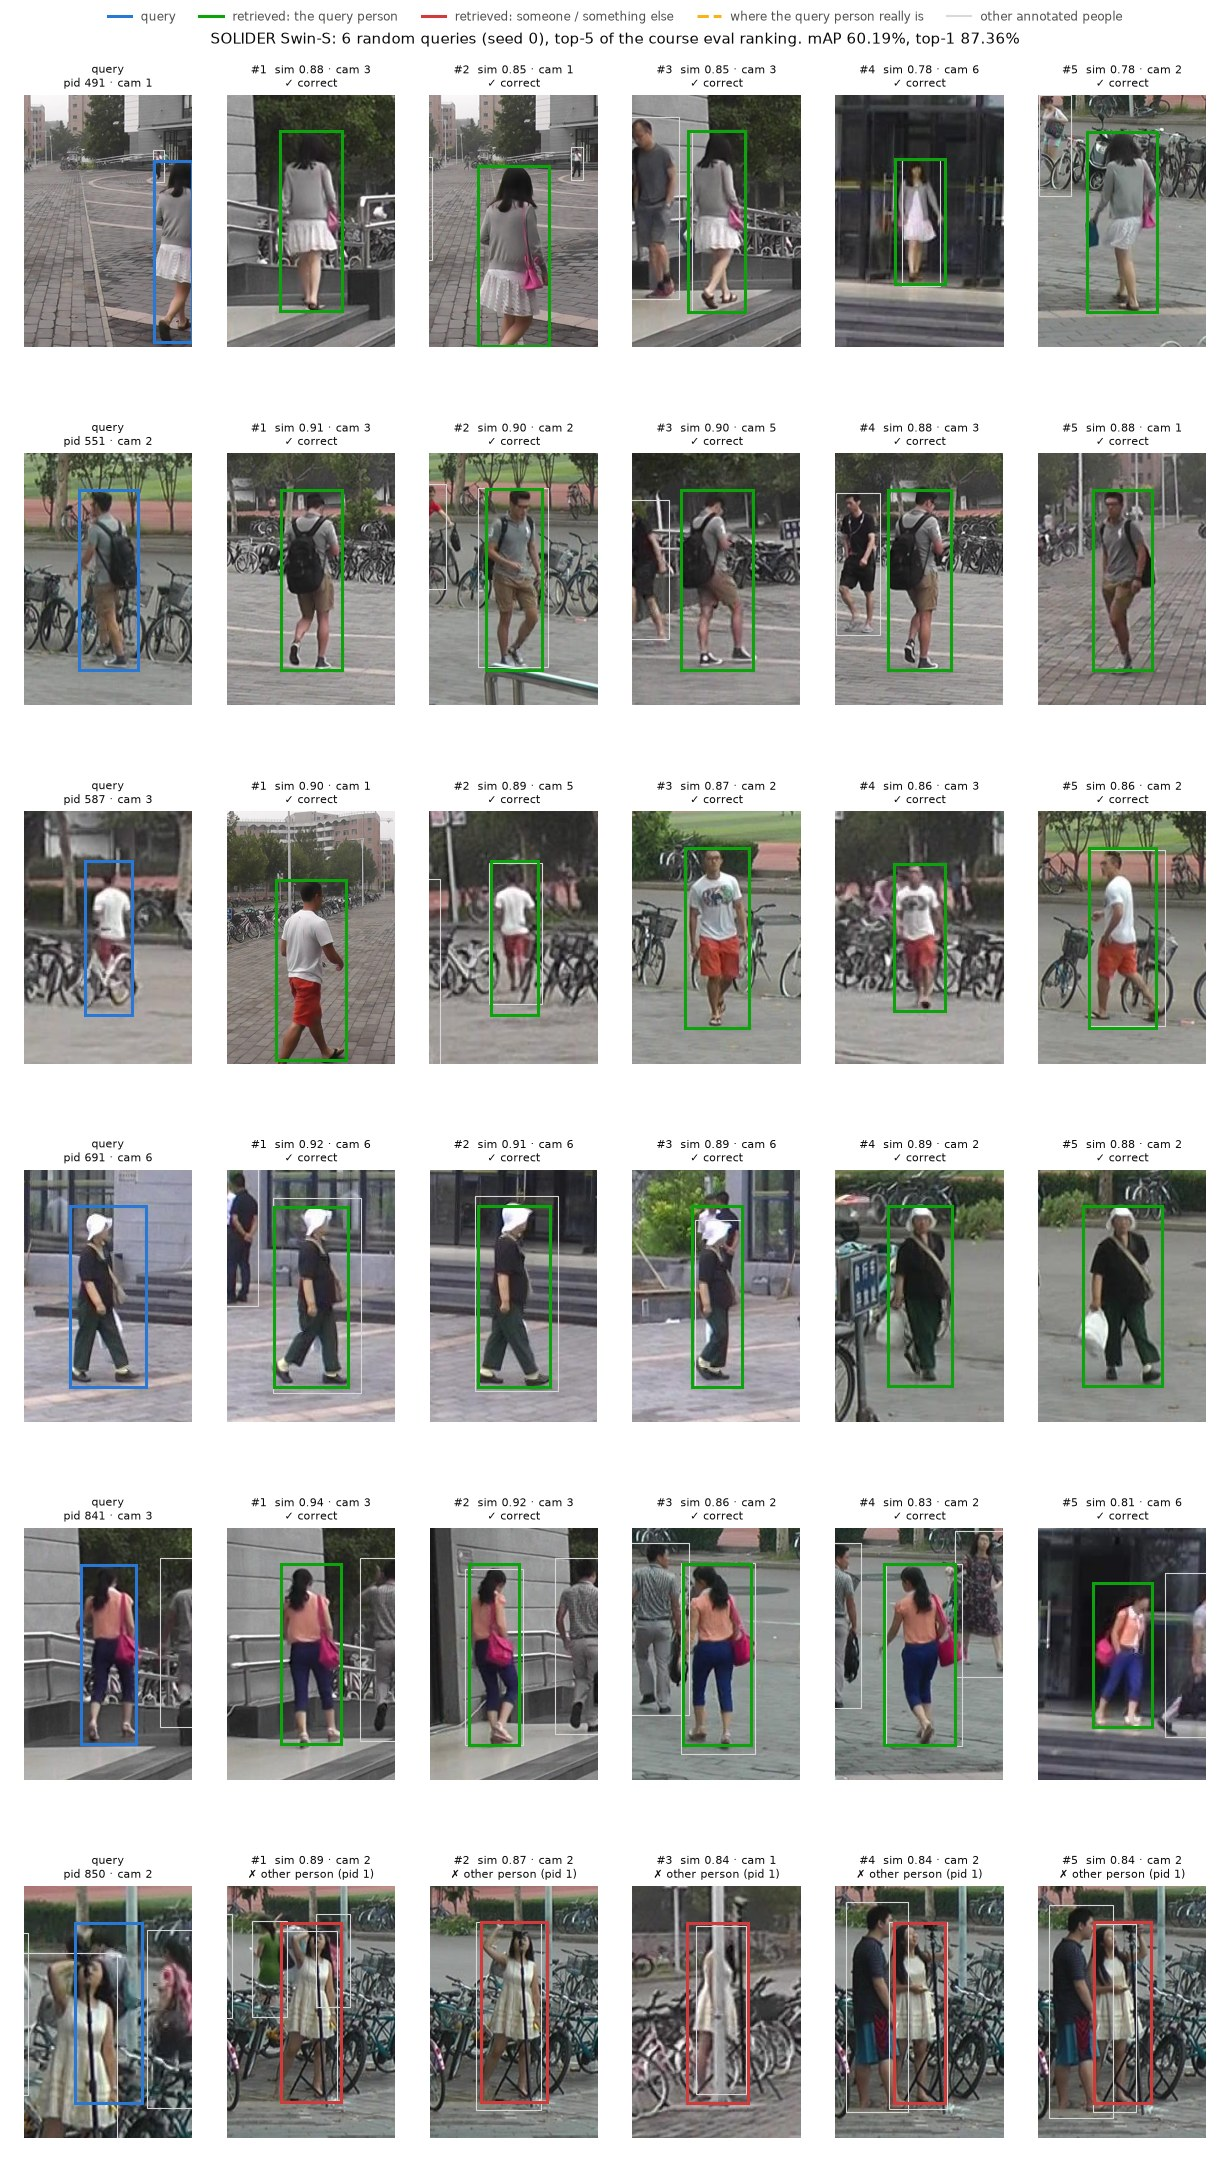

In [12]:
show(RESULTS / "solider_swin_s" / "search_random.jpg", width=900)

Five of the six random queries have the right person in all of the first five results, mostly from other cameras and with a different viewpoint (front and back views of the same person) and scale. The sixth (identity 850) is wrong five times, always with identity 1. These boxes appear to show the same woman as the query (same dress, same raised-arm pose, same camera), which suggests that PRW sometimes gives one person two identities. We cannot verify this, but it is a reminder that some of the measured errors may be errors of the labels.

#### Why the top-1 result is wrong

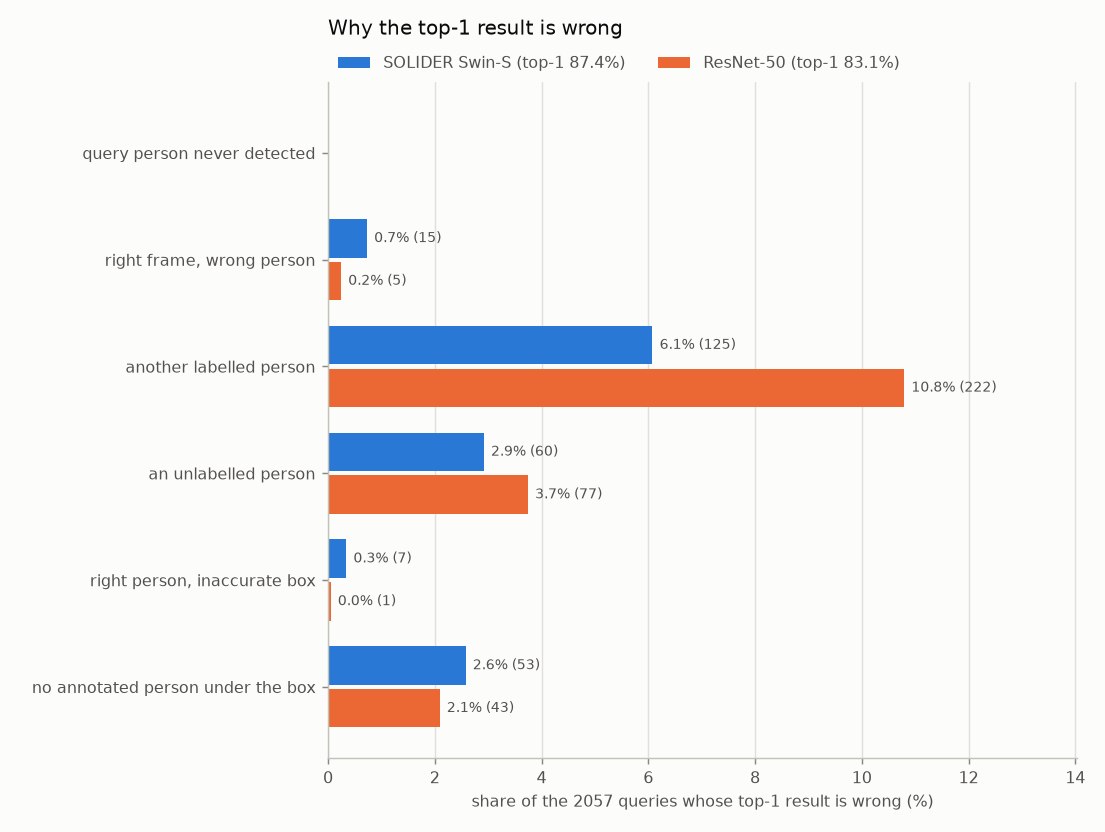

In [13]:
show(RESULTS / "top1_errors.png", width=800)

- Swin-S gets the top-1 result wrong for 260 queries (12.6%), ResNet-50 for 348 (16.9%).
- **The improvement comes from re-identification:** "another labelled person" errors drop from 222 to 125 and "unlabelled person" errors from 77 to 60.
- **Errors related to detection are slightly more frequent with Swin-S:** right frame but wrong person (15 against 5), inaccurate box (7 against 1), no annotated person (53 against 43). In total that is 75 against 49, the price of its weaker detector (see below).
- No query fails because its person is never detected: the query people are detected in 97.8% of their gallery appearances (98.2% with ResNet-50).
- When the first result is wrong, the right person is usually close: it is within the first 5 results for 94.2% of the queries (92.4% with ResNet-50).

#### What Swin-S fixes, and what it breaks

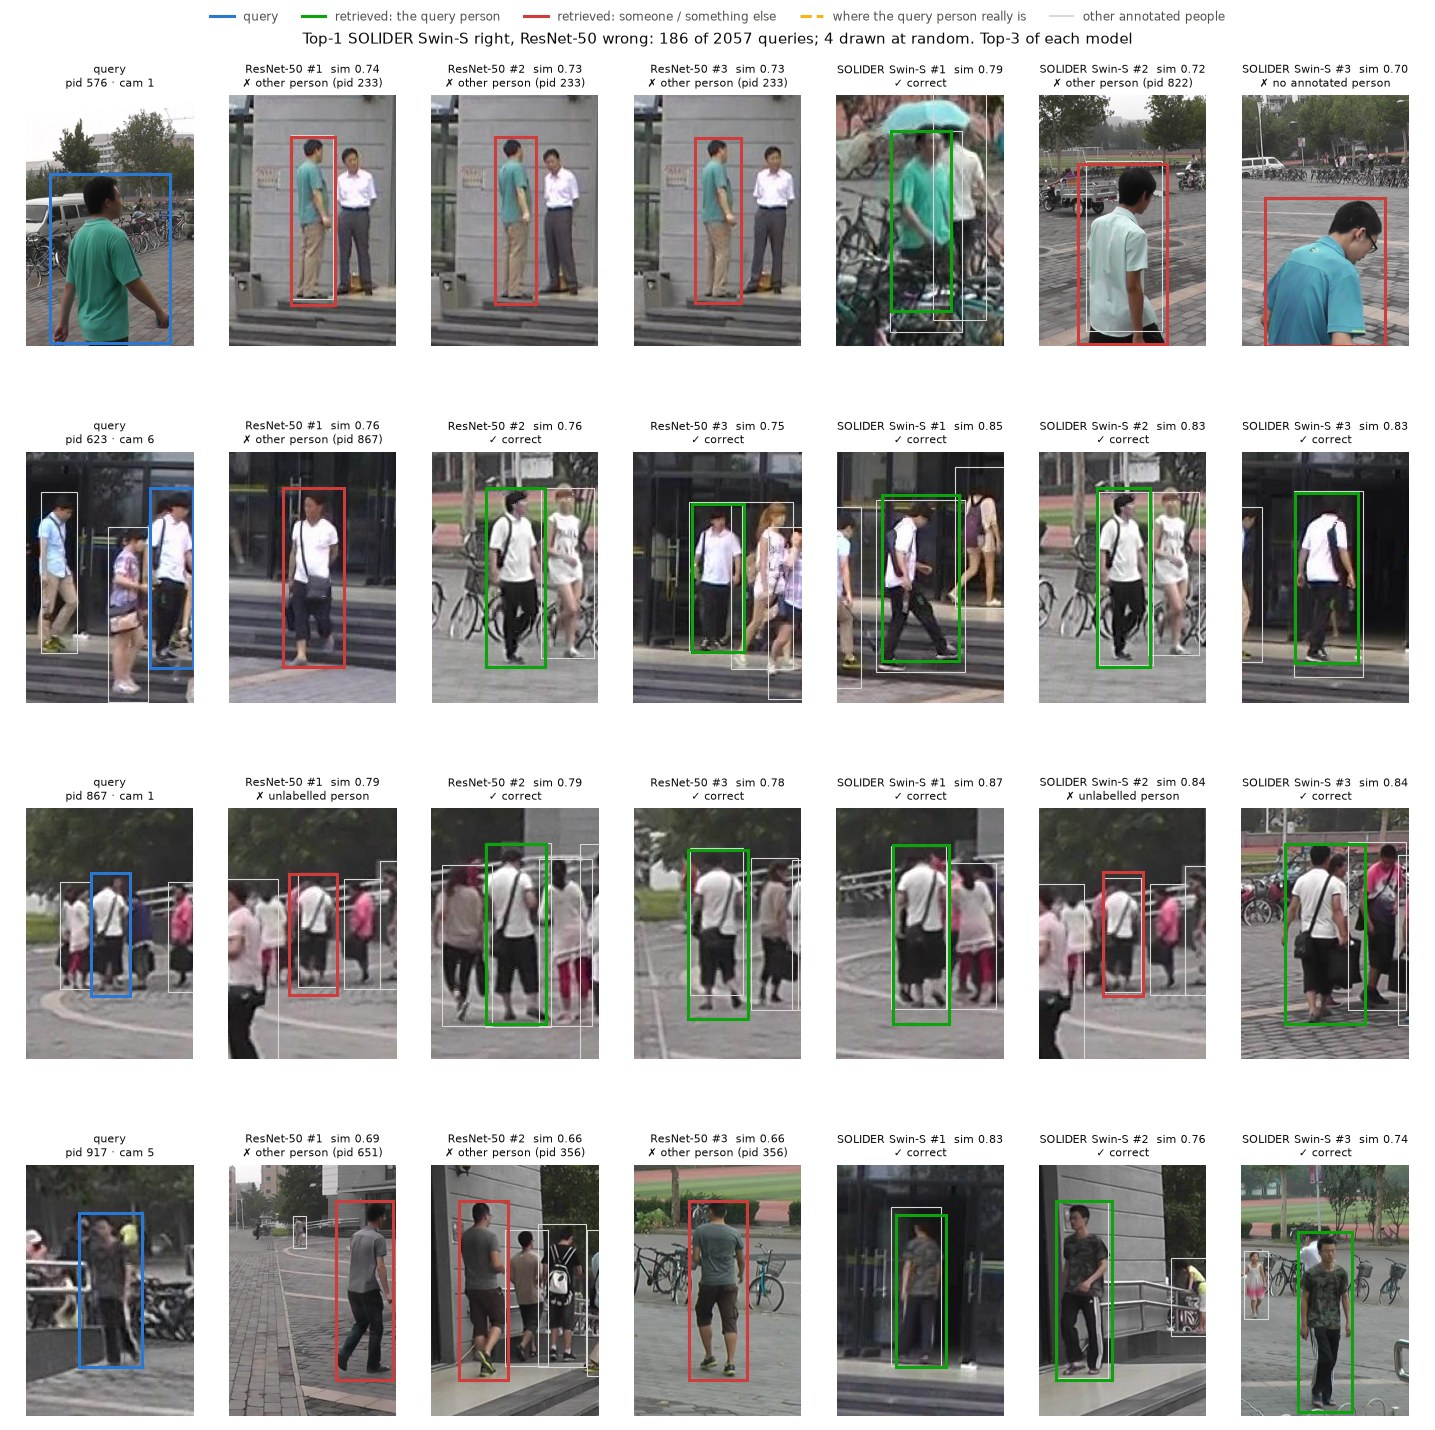

In [14]:
show(RESULTS / "compare_fixed.jpg")

In the random queries that Swin-S fixes, ResNet-50 retrieves people **wearing the same colours**: a man in a teal shirt for the query in green (identity 576), men in plain grey T-shirts for the camouflage shirt of identity 917. Often it retrieves the same wrong person in consecutive frames: PRW frames are sampled from video, so a wrong identity tends to repeat over several ranks. Swin-S matches finer cues: the camouflage pattern, the white shirt and shoulder bag of identity 867 in a crowd, and the green shirt of identity 576 under an umbrella. This fits SOLIDER's pre-training on images of people, whose features describe texture and body parts, not only the dominant colour.

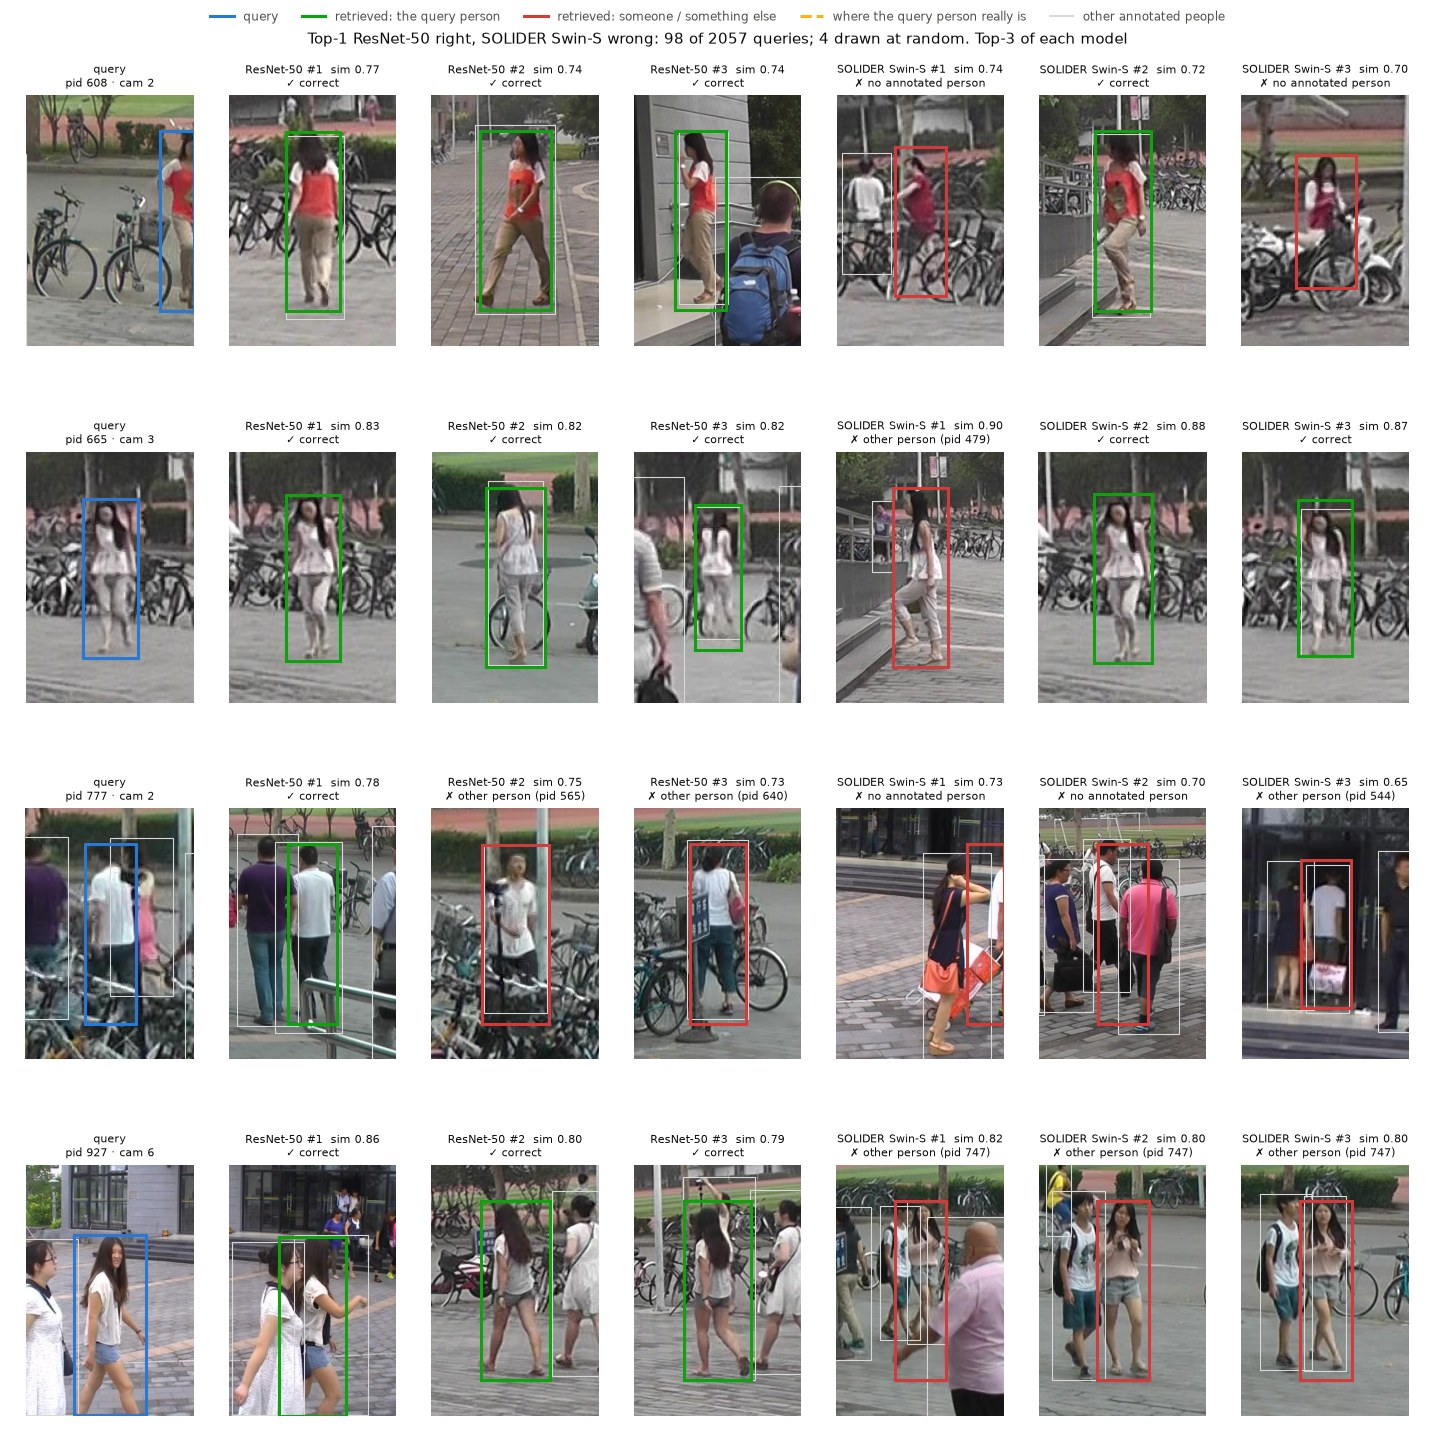

In [15]:
show(RESULTS / "compare_broken.jpg")

The queries that only ResNet-50 gets right are of two kinds. In two of the four examples, Swin-S retrieves a person with an almost identical outfit (identity 665 and identity 479: long dark hair, white top, light trousers; identity 927 and identity 747: long hair, light top, denim shorts) and ranks the right person second, or not in the first three. In the other two, the query is only partly visible (identity 608, cut by the image border; identity 777, occluded in a crowd), and the first results of Swin-S fall on unannotated people or on boxes between two people.

#### Look-alikes: the most frequent error (Swin-S)

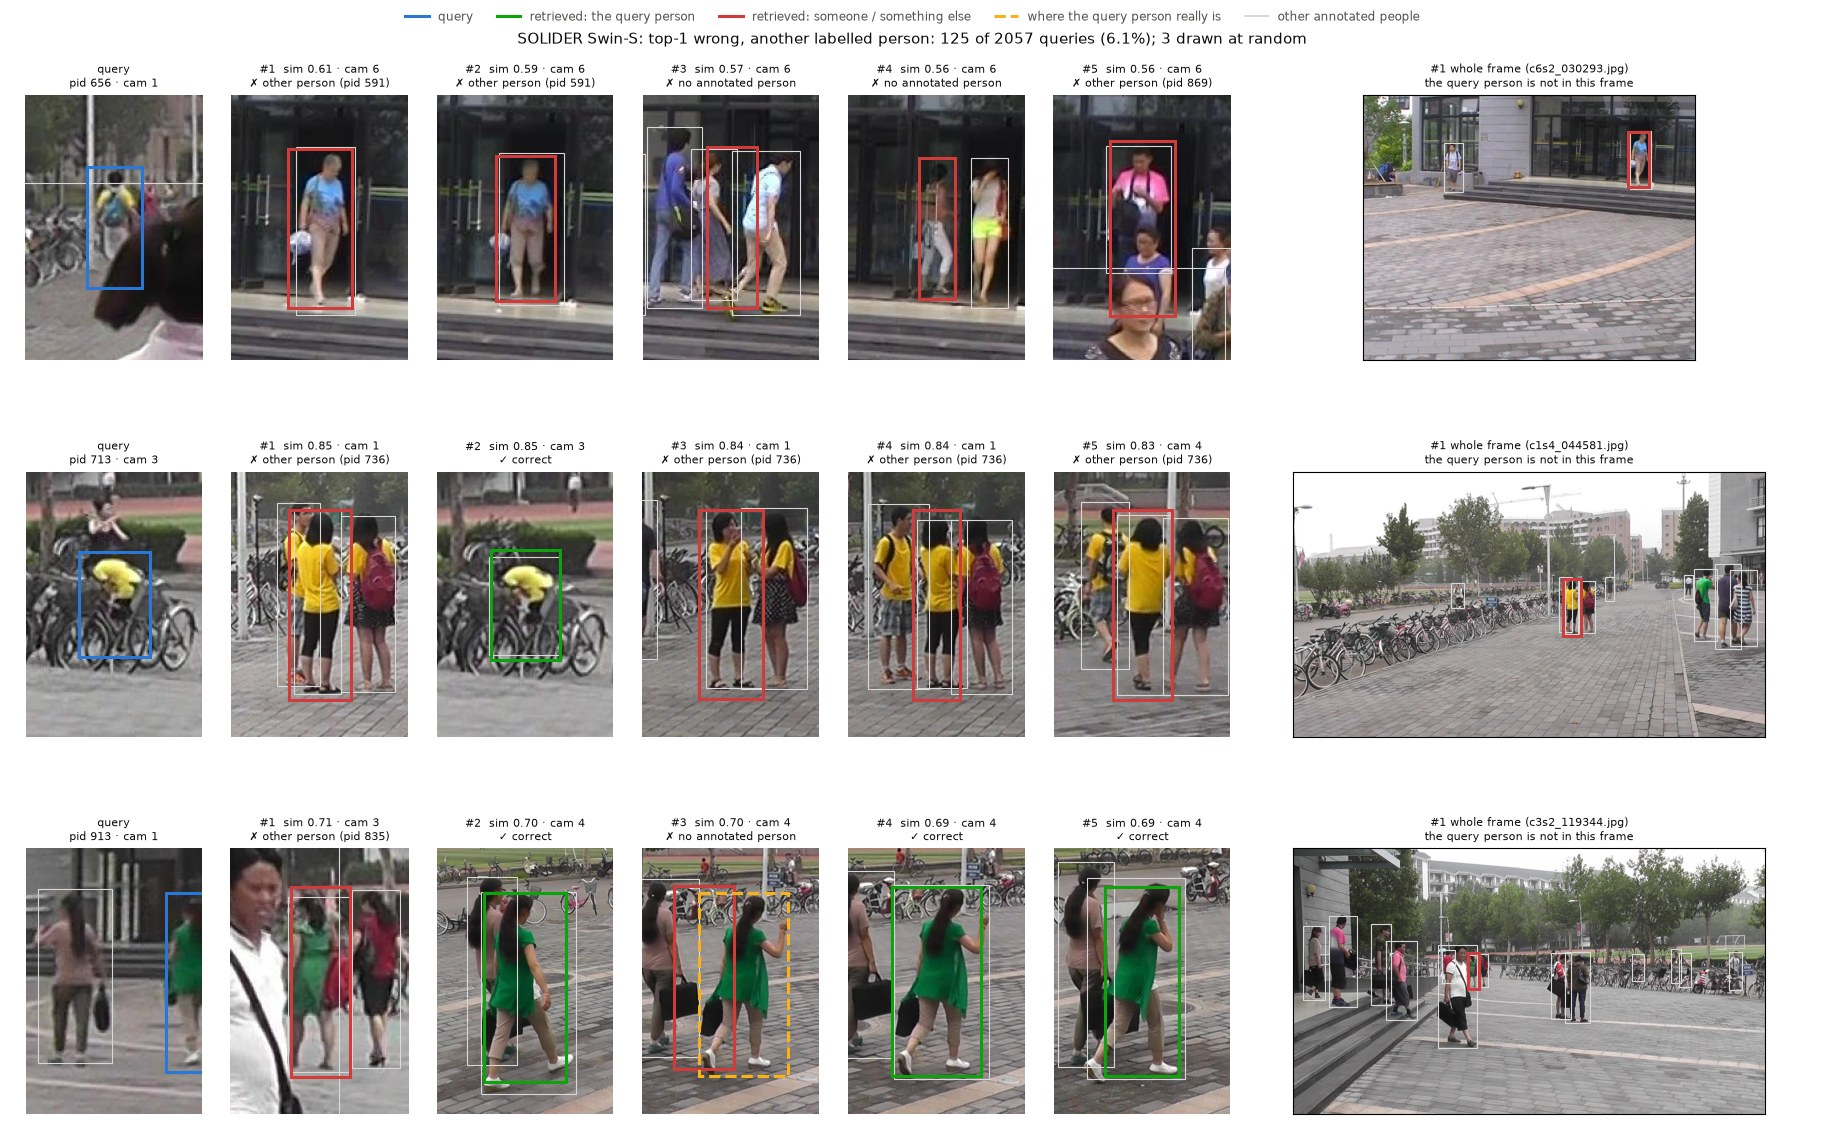

In [16]:
show(RESULTS / "solider_swin_s" / "failures_lookalike.jpg")

In the three random examples of the 125 "another labelled person" errors, the query itself is hard: largely hidden behind a person in the foreground (identity 656), bent over a bicycle (identity 713) or cut by the image border (identity 913). The wrong match wears the same colours (a blue top, the same yellow shirt, a green dress). In two of the three, the right person is the second result.

#### Gaps in the annotations (Swin-S)

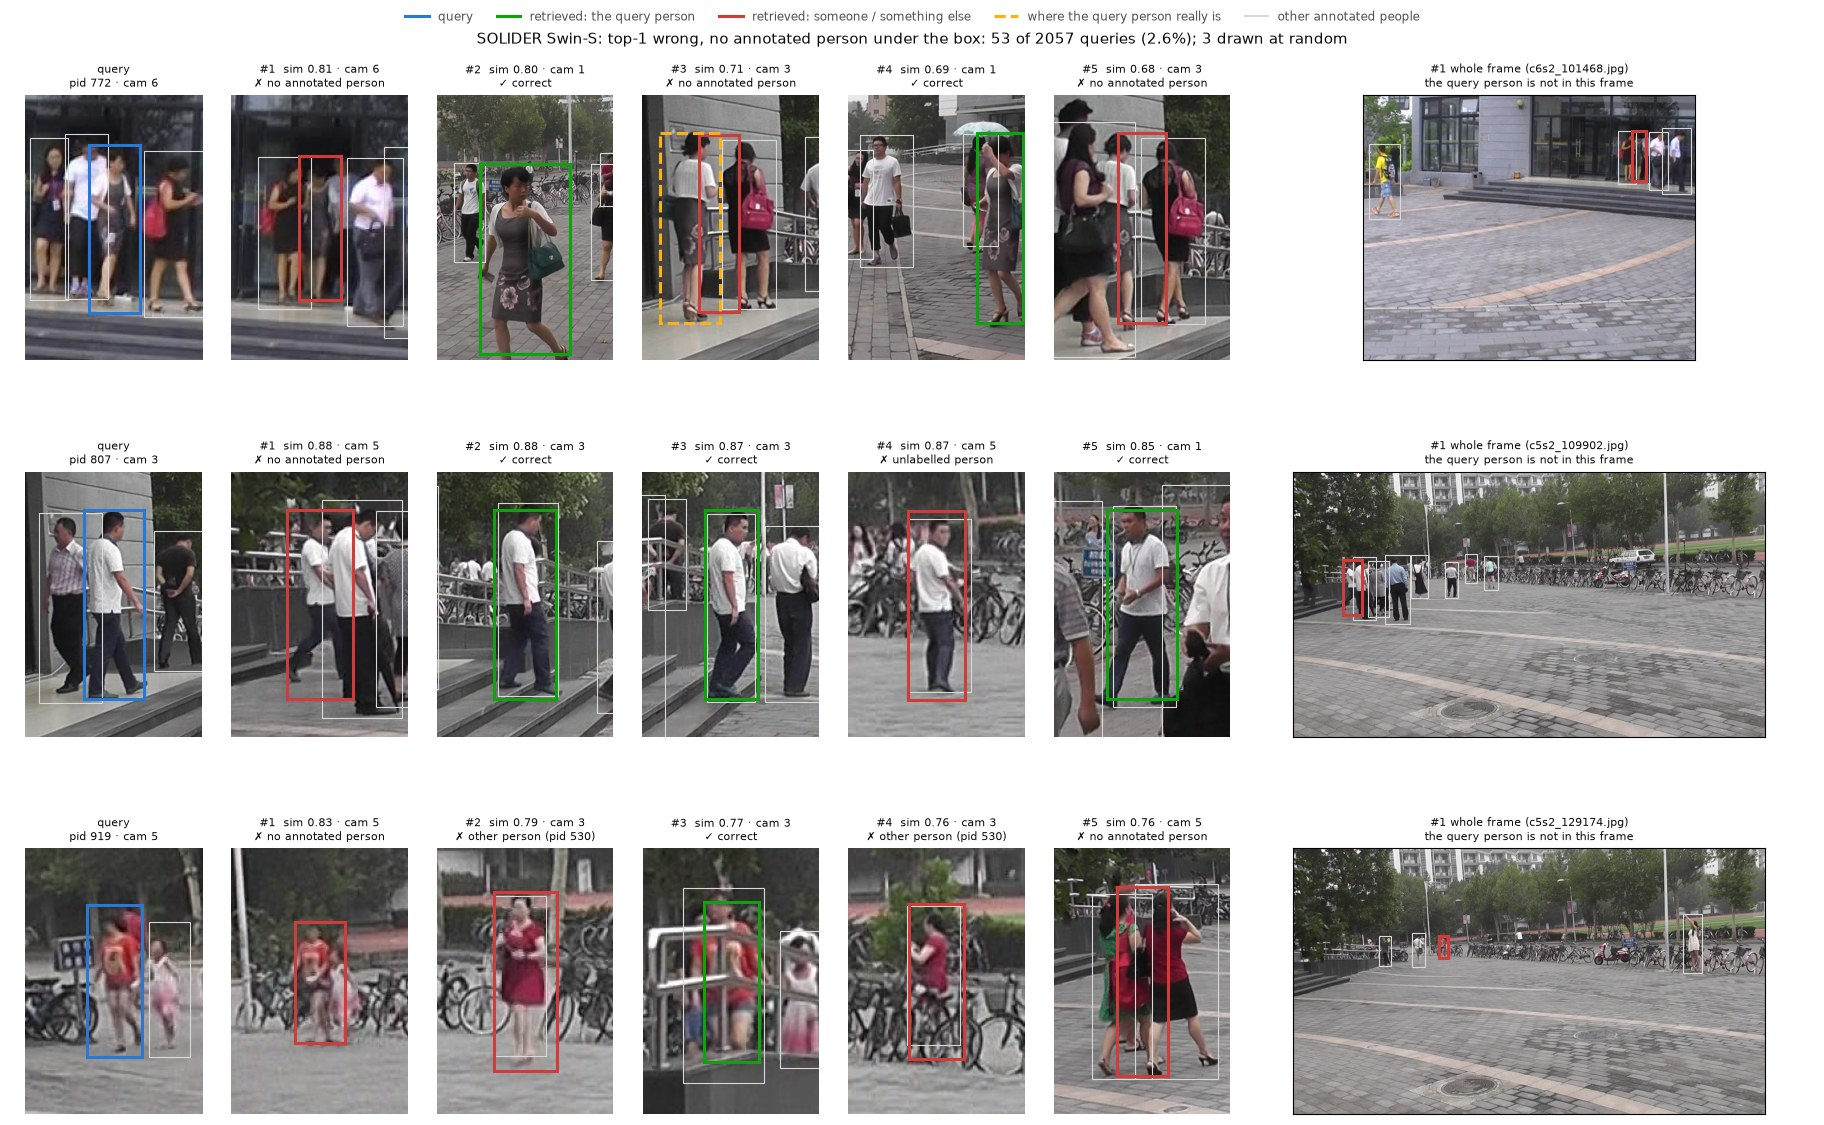

In [17]:
show(RESULTS / "solider_swin_s" / "failures_no_person.jpg")

In all three random examples of the 53 "no annotated person" errors, the first result is a real person who has no annotation in that frame. In two of them (identities 807 and 919) that person looks like the query person themselves, so the model is probably right and the evaluation counts it as an error. The same happens in detection: in the next figure some clearly visible people have no annotation, so their detections count as wrong. A part of the measured error is therefore annotation noise, which no model can remove.

#### Detection: small people

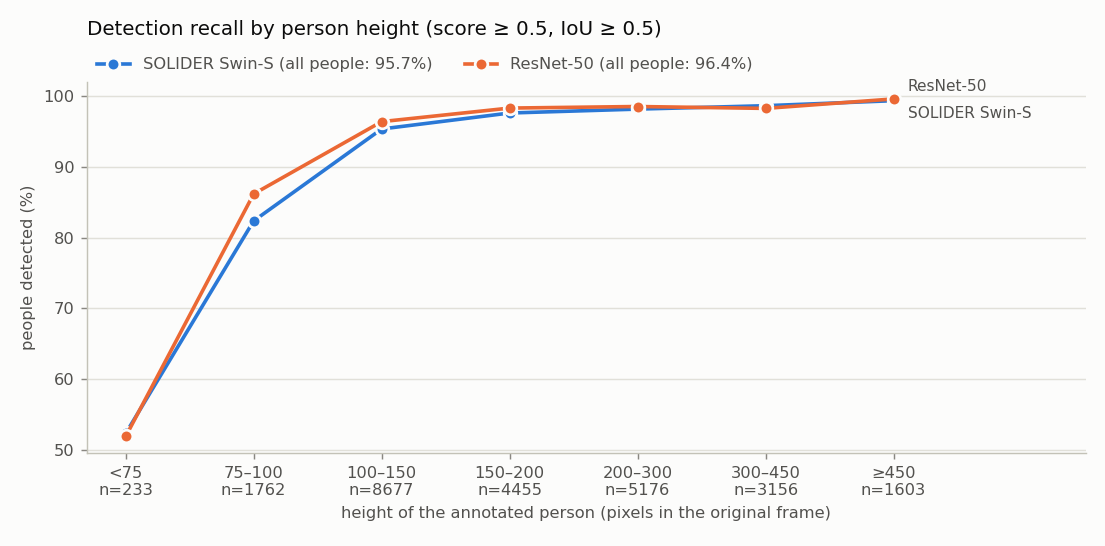

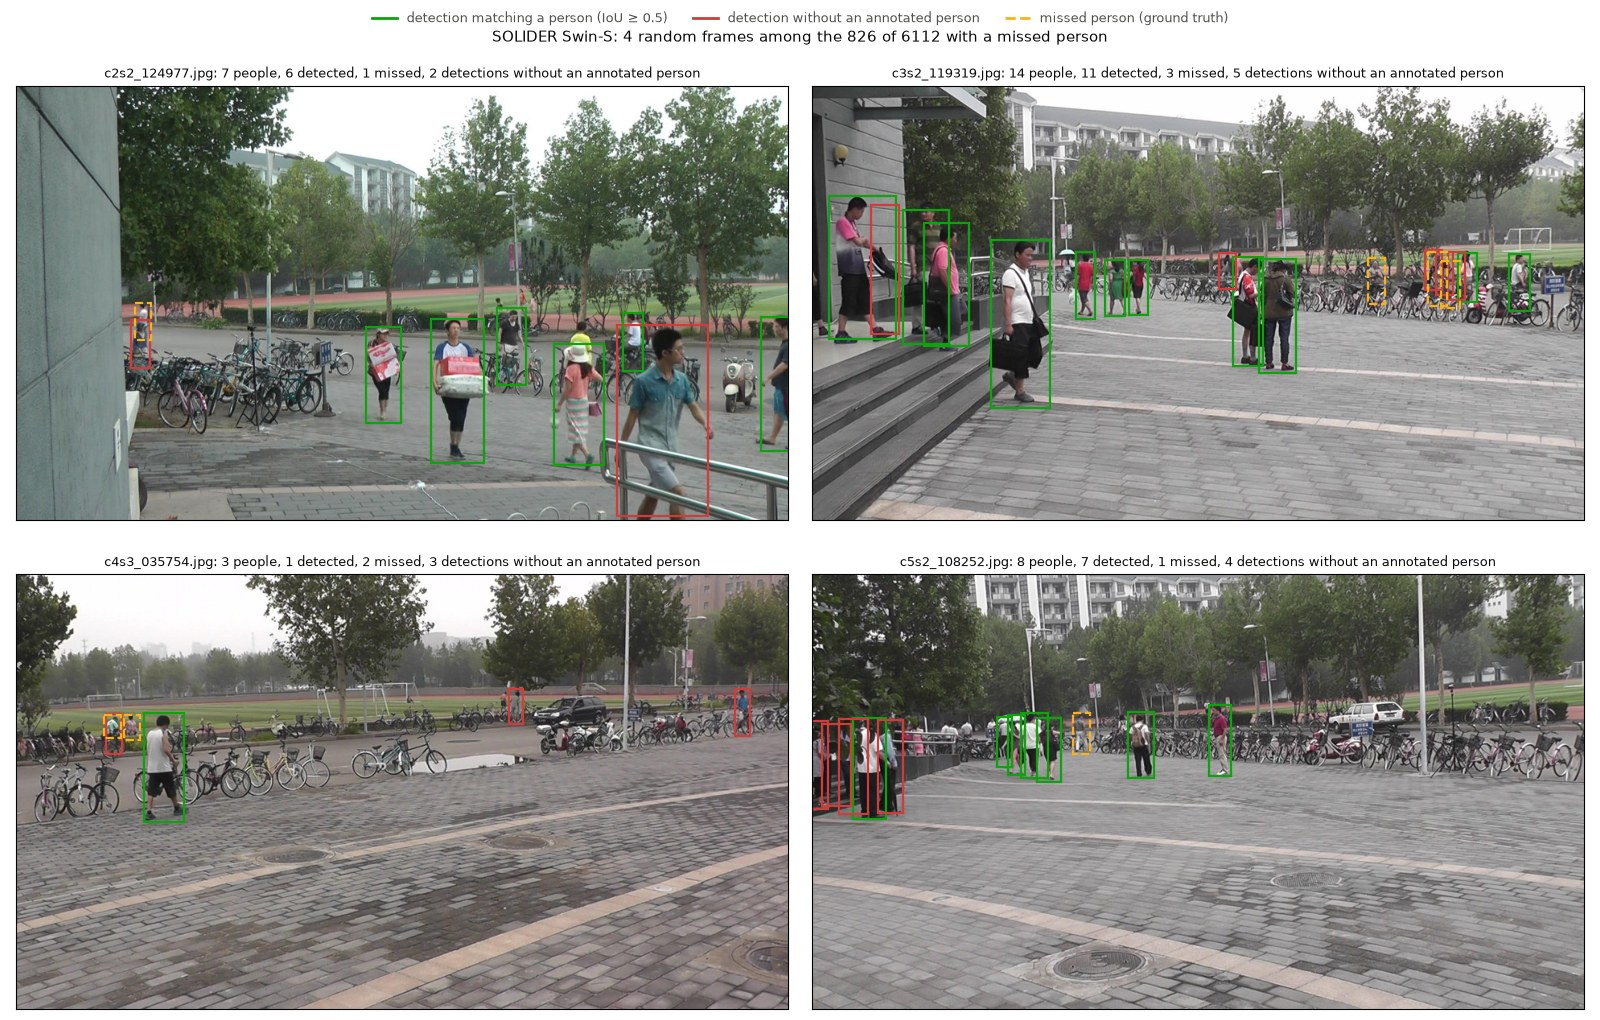

In [18]:
show(RESULTS / "recall_by_height.png", width=800)
show(RESULTS / "solider_swin_s" / "detections_misses.jpg")

Swin-S detects 95.66% of the annotated people, against 96.45% for ResNet-50, and the gap is concentrated on **small people**: 82.4% against 86.2% for people 75–100 px tall, and 95.3% against 96.4% at 100–150 px. Above 150 px both models detect more than 97.5% of the people; below 75 px both detect only about half. The frames with a missed person (826 of the 6,112 for Swin-S) show the typical case: distant people in groups, next to bicycles or partly hidden.

The frames of the five HD cameras are also downscaled before detection (1920×1080 to 1500×844, SeqNet's input size), so a person 100 px tall in them is 78 px tall for the network; the SD camera's 720×576 frames are instead enlarged to 1125×900. A plausible explanation for the gap is that Swin's first layer works on 4×4-pixel patches, while the first ResNet layers see finer detail. Some of the detections without an annotated person are clearly people, such as the man in the foreground of the first frame.

### 4.5 Analysis

1. **The backbone's pre-training is the main lever.** The course submission concluded (its Section 4.4) that embedding quality was no longer the limiting factor and that further gains should come from the matching step (CBGM), which the fixed evaluation function does not allow. The reimplementation shows the opposite. With SeqNet's matching unchanged, the human-centric pre-training of SOLIDER alone adds 13.8 mAP, and the qualitative analysis attributes the gain to fewer confusions between different people (222 → 125 top-1 errors).

2. **Training loss is a poor predictor of test accuracy.** ResNet-50 ends with a lower OIM loss than Swin-S but is 13.8 mAP worse. Separating the training identities is not the same as generalising to new ones; what generalises is decided mostly by the pre-training.

3. **For this metric, re-identification matters more than detection.** Swin-S detects slightly worse, but its query people are still found in 97.8% of their appearances, so the recall factor of the per-query AP barely changes, while the ranking improves a lot. The head learning-rate experiment confirms the asymmetry: a small gain in detection at the expense of the embedding lowered the mAP.

4. **Flip test-time augmentation** adds 2.9 mAP for twice the re-identification cost at test time. A plausible explanation is that averaging the two views makes the embedding less sensitive to left–right asymmetries of pose and of carried objects.

5. **The remaining errors** are mostly look-alikes with hard queries (occlusion, truncation, unusual poses), small distant people, and annotation gaps. The first two suggest the next steps: a higher input resolution or multi-scale training (as in AlignPS, Yan et al., CVPR 2021) for small people, and a stronger backbone (e.g. Swin-B). The third limits what any model can score.

### 4.6 Limitations

- **One training run per configuration.** Several seeds were not affordable (6 hours per Swin-S run), so small differences, well below 1 mAP, should not be over-interpreted. The −1.40 mAP of the head learning-rate experiment is larger than that, but it also comes from a single run.
- **Flip test-time augmentation** is not used in the published results; the like-for-like comparison with them is 60.19.
- **No validation split.** PRW has none. The recipes are the published ones and `det_thresh` makes no difference, so nothing was tuned on the test set. The head learning-rate experiment was evaluated on the test set and is reported whatever its outcome.
- **No CBGM** or other gallery-level re-ranking: they are part of the evaluation function, which is fixed.
- **The qualitative labels rely on the annotations.** "No annotated person" mixes false detections and unannotated people; we inspected the random samples by eye, not every case.
- **The checkpoints are not in the repository** (hundreds of MB each), so `RUN_EVAL` needs them on the cluster.

## 5. Conclusion

A faithful reimplementation of SeqNet, trained with the published recipe, raised the course submission from 27.21% to 46.40% mAP and reproduced the SeqNet paper. Replacing its ImageNet ResNet-50 with SOLIDER's Swin-S, pre-trained on images of people, reached 60.19% mAP / 87.36% top-1 (slightly above the result published for the same model), and 63.06% / 88.48% with flip test-time augmentation, all with the unchanged course evaluation function. The qualitative analysis shows where the gain comes from: far fewer confusions between people with similar clothing. It also shows what remains: hard queries, small distant people and gaps in the annotations.

### References

- L. Zheng et al., *Person Re-identification in the Wild*, CVPR 2017 (PRW).
- T. Xiao et al., *Joint Detection and Identification Feature Learning for Person Search*, CVPR 2017 (OIM).
- D. Chen et al., *Norm-Aware Embedding for Efficient Person Search*, CVPR 2020 (NAE).
- Z. Li and D. Miao, *Sequential End-to-end Network for Efficient Person Search*, AAAI 2021 (SeqNet; code: github.com/serend1p1ty/SeqNet).
- D. Fu et al., *Unsupervised Pre-training for Person Re-identification*, CVPR 2021 (LUPerson).
- Y. Yan et al., *Anchor-Free Person Search*, CVPR 2021 (AlignPS).
- W. Chen et al., *Beyond Appearance: a Semantic Controllable Self-Supervised Learning Framework for Human-Centric Visual Tasks*, CVPR 2023 (SOLIDER; code: github.com/tinyvision/SOLIDER and SOLIDER-PersonSearch).